In [1]:
%load_ext autoreload
%autoreload 2


In [13]:
from src.data import load_data
import pandas as pd

# Разрешить отображать все колонки без сокращений по горизонтали
pd.set_option('display.max_columns', None)

# Ограничить ширину колонок, чтобы длинный текст (например, имена) не растягивал таблицу
pd.set_option('display.max_colwidth', 20)

# Округлить отображение float-чисел (например, стоимости билета Fare) до 2 знаков после запятой
pd.set_option('display.float_format', '{:.2f}'.format)


from main import train, test


In [4]:
# выявляем людей с отсутсвующим портом отправления
missing_embarked = train[train['Embarked'].isnull()]
print(missing_embarked[['Pclass', 'Ticket']])
print('*' * 40)
# фильтруем людей, чтобы найти 
filtered_passengers = train[(train['Pclass'] == 1) & (train['Fare'] >= 75) & (train['Fare'] <= 85 )]

un = filtered_passengers['Embarked'].value_counts()
print(un)

     Pclass  Ticket
61        1  113572
829       1  113572
****************************************
Embarked
C    16
S    13
Name: count, dtype: int64


In [6]:
# как точнее заполнить возраст
missing_age = train[train['Age'].isnull()]
#print(missing_age[['Fare', 'Pclass', 'Sex']].value_counts())

test_age = train[
    (train['Pclass'] == 3) & 
    (train['Fare'] <= 8.30) &
    (train['Age'].notnull())
    ]
print(test_age['Age'].describe())

count   189.00
mean     28.35
std      10.90
min      13.00
25%      21.00
50%      25.00
75%      33.00
max      74.00
Name: Age, dtype: float64


In [7]:
passenger = test['Fare'].isnull()
print(test[passenger][['Pclass', 'Name', 'Sex', 'Age', 'Embarked']])
print('*' * 40)
find_median = test[
    (test['Pclass'] == 3) &
    (test['Sex'] == 'male') &
    (test['Age'] >= 50)
]
print(find_median['Fare'])

     Pclass                Name   Sex   Age Embarked
152       3  Storey, Mr. Thomas  male 60.50        S
****************************************
25    14.50
152     NaN
Name: Fare, dtype: float64


эпох: 200
loss первая / последняя: 0.6834 / 0.3551


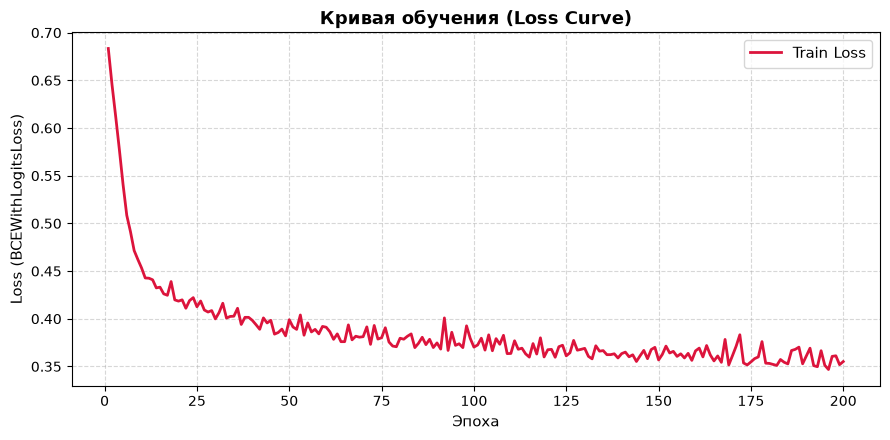

In [17]:
from config import config
from src.data import load_data
from src.eda import plot_loss_curve
from src.models.mlp import ModelEngine
from src.validation import create_folds
from main import prepare

train, test = load_data(config)
df_train, df_test, test_ids, features = prepare(train, test, config)
df = create_folds(df_train, config)

train_fold = df[df["kfold"] != 0]
X_train = train_fold[features]
y_train = train_fold[config.columns.target]

engine = ModelEngine(
    len(features),
    lr=config.mlp.lr,
    epochs=config.mlp.epochs,
    batch_size=config.mlp.batch_size,
)
engine.fit(X_train, y_train)
print(f"эпох: {len(engine.loss_history)}")
print(f"loss первая / последняя: {engine.loss_history[0]:.4f} / {engine.loss_history[-1]:.4f}")
plot_loss_curve(engine.loss_history)

In [16]:

from config import config
from src.data import load_data
from main import prepare

train, test = load_data(config)
df_train, df_test, test_ids, features = prepare(train, test, config)

missing_on_test = [col for col in features if col not in df_test.columns]
extra_on_test = [col for col in df_test.columns if col not in features]

print("колонок у модели:", len(features))
print("нет на тесте:", missing_on_test)
print("лишние на тесте:", extra_on_test)
print("train", df_train[features].shape)
print("test", df_test.shape)
print("id теста", len(test_ids))

колонок у модели: 13
нет на тесте: []
лишние на тесте: []
train (891, 13)
test (418, 13)
id теста 418


In [15]:
train, test = load_data(config)

Embarked = test["Embarked"]
print(Embarked.isnull().value_counts())

Embarked
False    418
Name: count, dtype: int64
